# Assignment 47 — Week 4, Day 1
## Topic: Pandas — Cleaning Data

**Objective:** Complete the exercise on Pandas data-cleaning techniques.

**Reference:** https://www.w3schools.com/python/pandas_cleaning.asp

Data cleaning means fixing bad data in a data set. This notebook uses `dirtydata_full.csv`, the W3Schools practice file with 32 workouts, which must be in the same folder.

**Diagram:** Each kind of bad data, where it appears in the file, and how it is fixed.

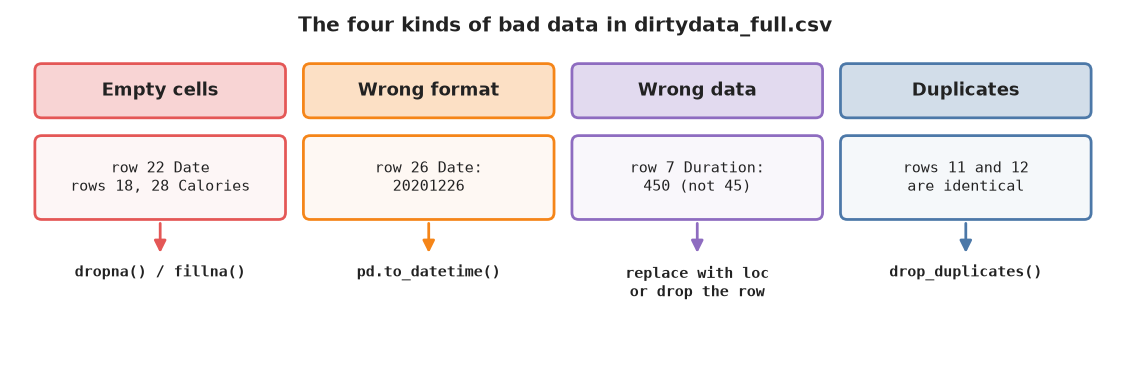

**Look at the dirty data**

In [1]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

print(df.to_string())

    Duration        Date  Pulse  Maxpulse  Calories
0         60  2020/12/01    110       130     409.1
1         60  2020/12/02    117       145     479.0
2         60  2020/12/03    103       135     340.0
3         45  2020/12/04    109       175     282.4
4         45  2020/12/05    117       148     406.0
5         60  2020/12/06    102       127     300.0
6         60  2020/12/07    110       136     374.0
7        450  2020/12/08    104       134     253.3
8         30  2020/12/09    109       133     195.1
9         60  2020/12/10     98       124     269.0
10        60  2020/12/11    103       147     329.3
11        60  2020/12/12    100       120     250.7
12        60  2020/12/12    100       120     250.7
13        60  2020/12/13    106       128     345.3
14        60  2020/12/14    104       132     379.3
15        60  2020/12/15     98       123     275.0
16        60  2020/12/16     98       120     215.2
17        60  2020/12/17    100       120     300.0
18        45

**Explanation:** The data set has empty cells (Date in row 22, Calories in rows 18 and 28), a wrong format (Date in row 26), wrong data (Duration in row 7) and duplicates (rows 11 and 12).

## 1. Empty cells

**Diagram:** Empty cells can be removed with their row, or replaced with a value.

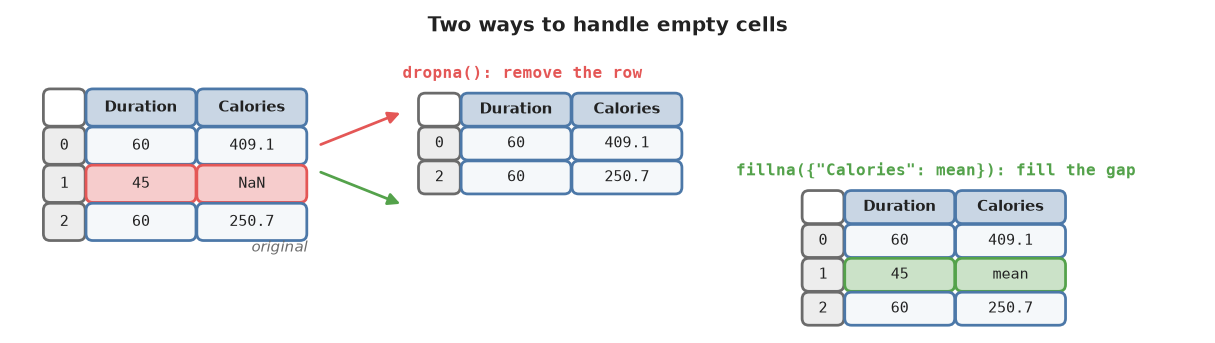

**Remove rows with empty cells**

In [2]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

new_df = df.dropna()

print(new_df.to_string())
print("Rows before:", len(df), "| rows after:", len(new_df))

    Duration        Date  Pulse  Maxpulse  Calories
0         60  2020/12/01    110       130     409.1
1         60  2020/12/02    117       145     479.0
2         60  2020/12/03    103       135     340.0
3         45  2020/12/04    109       175     282.4
4         45  2020/12/05    117       148     406.0
5         60  2020/12/06    102       127     300.0
6         60  2020/12/07    110       136     374.0
7        450  2020/12/08    104       134     253.3
8         30  2020/12/09    109       133     195.1
9         60  2020/12/10     98       124     269.0
10        60  2020/12/11    103       147     329.3
11        60  2020/12/12    100       120     250.7
12        60  2020/12/12    100       120     250.7
13        60  2020/12/13    106       128     345.3
14        60  2020/12/14    104       132     379.3
15        60  2020/12/15     98       123     275.0
16        60  2020/12/16     98       120     215.2
17        60  2020/12/17    100       120     300.0
19        60

**Explanation:** dropna() returns a new DataFrame without the rows that contain empty cells, and leaves the original unchanged. Data sets are often large, so removing a few rows usually does not affect the result much.

**Remove rows in place**

In [3]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

df.dropna(inplace=True)

print(df.to_string())

    Duration        Date  Pulse  Maxpulse  Calories
0         60  2020/12/01    110       130     409.1
1         60  2020/12/02    117       145     479.0
2         60  2020/12/03    103       135     340.0
3         45  2020/12/04    109       175     282.4
4         45  2020/12/05    117       148     406.0
5         60  2020/12/06    102       127     300.0
6         60  2020/12/07    110       136     374.0
7        450  2020/12/08    104       134     253.3
8         30  2020/12/09    109       133     195.1
9         60  2020/12/10     98       124     269.0
10        60  2020/12/11    103       147     329.3
11        60  2020/12/12    100       120     250.7
12        60  2020/12/12    100       120     250.7
13        60  2020/12/13    106       128     345.3
14        60  2020/12/14    104       132     379.3
15        60  2020/12/15     98       123     275.0
16        60  2020/12/16     98       120     215.2
17        60  2020/12/17    100       120     300.0
19        60

**Explanation:** inplace=True changes the original DataFrame instead of returning a new one.

**Replace empty cells with a value**

In [4]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

try:
    df.fillna(130, inplace=True)
    print(df.loc[[18, 22, 28]])
except TypeError as error:
    print("TypeError:", error)

print(df.select_dtypes("number").fillna(130).loc[[18, 28]])

TypeError: Invalid value '130' for dtype 'str'. Value should be a string or missing value, got 'int' instead.
    Duration  Pulse  Maxpulse  Calories
18        45     90       112     130.0
28        60    103       132     130.0


**Explanation:** fillna() replaces empty cells with a value, so no rows are lost. The W3Schools example fills every empty cell with 130. In Pandas 3 the Date column holds text, so putting the number 130 into it raises a TypeError. Filling only the numeric columns works, but the safest approach is to fill one column at a time, as in the next example.

**Replace empty cells only in one column**

In [5]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

df.fillna({"Calories": 130}, inplace=True)

print(df.loc[[18, 22, 28]])

    Duration        Date  Pulse  Maxpulse  Calories
18        45  2020/12/18     90       112     130.0
22        45         NaN    100       119     282.0
28        60  2020/12/28    103       132     130.0


**Explanation:** A dictionary passed to fillna() names the column to fill, so only the empty Calories cells become 130 and the empty Date is left alone.

**Replace with the mean, median or mode**

In [6]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

x_mean = df["Calories"].mean()
x_median = df["Calories"].median()
x_mode = df["Calories"].mode()[0]
print("Mean:", round(x_mean, 2), "| Median:", x_median, "| Mode:", x_mode)

df.fillna({"Calories": x_mean}, inplace=True)
print(df.loc[[18, 28]])

Mean: 304.68 | Median: 291.2 | Mode: 300.0
    Duration        Date  Pulse  Maxpulse  Calories
18        45  2020/12/18     90       112    304.68
28        60  2020/12/28    103       132    304.68


**Explanation:** A common way to fill empty cells is with the column's mean (average), median (middle value) or mode (most frequent value). Here the mean is used.

## 2. Data in the wrong format

**Convert the Date column to dates**

In [7]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

df["Date"] = pd.to_datetime(df["Date"], format="mixed")

print(df.loc[[21, 22, 26]])

    Duration       Date  Pulse  Maxpulse  Calories
21        60 2020-12-21    108       131     364.2
22        45        NaT    100       119     282.0
26        60 2020-12-26    100       120     250.0


**Explanation:** Cells in the wrong format make analysis difficult. to_datetime() converts every value to a date: 20201226 becomes 2020-12-26, and the empty date becomes NaT (Not a Time).

**Remove the row with no date**

In [8]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")
df["Date"] = pd.to_datetime(df["Date"], format="mixed")

df.dropna(subset=["Date"], inplace=True)

print(df.dtypes)
print("Rows:", len(df))

Duration             int64
Date        datetime64[us]
Pulse                int64
Maxpulse             int64
Calories           float64
dtype: object
Rows: 31


**Explanation:** dropna(subset=['Date']) removes only the rows where Date is empty, so the column is now a proper datetime type.

## 3. Wrong data

**Replace a wrong value**

In [9]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

print("Before:", df.loc[7, "Duration"])
df.loc[7, "Duration"] = 45
print("After:", df.loc[7, "Duration"])

Before: 450
After: 45


**Explanation:** A workout of 450 minutes is almost certainly a typing mistake for 45. loc sets the value in row 7 directly.

**Replace wrong values with a rule**

In [10]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

for x in df.index:
    if df.loc[x, "Duration"] > 120:
        df.loc[x, "Duration"] = 120

print(df["Duration"].max())

120


**Explanation:** For larger data sets, a rule can be applied to every row: any duration over 120 minutes is set to 120.

**Remove rows with wrong data**

In [11]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

for x in df.index:
    if df.loc[x, "Duration"] > 120:
        df.drop(x, inplace=True)

print("Rows left:", len(df))
print(df["Duration"].max())

Rows left: 31
60


**Explanation:** Another option is to delete the rows that contain wrong data with drop().

## 4. Duplicates

**Find duplicates**

In [12]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

print(df.duplicated().to_string())

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12     True
13    False
14    False
15    False
16    False
17    False
18    False
19    False
20    False
21    False
22    False
23    False
24    False
25    False
26    False
27    False
28    False
29    False
30    False
31    False


**Explanation:** duplicated() returns True for every row that is an exact copy of an earlier row. Row 12 is True because it repeats row 11.

**Remove duplicates**

In [13]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

df.drop_duplicates(inplace=True)

print("Rows left:", len(df))
print(df.duplicated().any())

Rows left: 31
False


**Explanation:** drop_duplicates() removes the repeated rows, so no duplicates remain.

## Putting it all together

**Clean the whole data set**

In [14]:
import pandas as pd

df = pd.read_csv("dirtydata_full.csv")

df["Date"] = pd.to_datetime(df["Date"], format="mixed")
df.dropna(subset=["Date"], inplace=True)
df.fillna({"Calories": df["Calories"].mean()}, inplace=True)
df.loc[df["Duration"] > 120, "Duration"] = 120
df.drop_duplicates(inplace=True)

df.info()

<class 'pandas.DataFrame'>
Index: 30 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Duration  30 non-null     int64         
 1   Date      30 non-null     datetime64[us]
 2   Pulse     30 non-null     int64         
 3   Maxpulse  30 non-null     int64         
 4   Calories  30 non-null     float64       
dtypes: datetime64[us](1), float64(1), int64(3)
memory usage: 1.4 KB


**Explanation:** All four fixes applied together give a clean data set with correct types, no empty cells, no unrealistic durations and no duplicate rows.

## Observation

- Bad data can be empty cells, data in the wrong format, wrong data, or duplicates.
- dropna() removes rows with empty cells; fillna() replaces them, ideally one column at a time and often with the mean, median or mode.
- to_datetime() converts mixed date formats, and dropna(subset=...) removes rows where a key column is empty.
- Wrong values can be fixed with loc, capped with a rule, or removed with drop().
- duplicated() finds repeated rows and drop_duplicates() removes them.

## Conclusion

Cleaning is an essential step before analysis, because bad data leads to wrong results. Pandas provides a short, clear method for each kind of problem.